# BÀI THỰC HÀNH 2 — Data Understanding, EDA & Preprocessing

**Phiên bản:** STUDENT TODO

**Dataset:** UCI Student Performance — `student-por.csv`

- Trang UCI: https://archive.ics.uci.edu/dataset/320/student%2Bperformance
- ZIP trực tiếp: https://archive.ics.uci.edu/static/public/320/student%2Bperformance.zip
- Citation: Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. DOI: 10.24432/C5TG7T.

> **Lưu ý:** Nếu chạy trên Google Colab/Jupyter có Internet, notebook có thể tự tải ZIP chính thức. Nếu môi trường không có Internet, hãy tải `student.zip`, giải nén và đặt `student-por.csv` cùng thư mục notebook.

In [38]:
# Cell thiết lập chung - được phép chạy nguyên trạng
from pathlib import Path
import io, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = Path('student-por.csv')
UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/320/student%2Bperformance.zip'

def ensure_dataset():
    if DATA_FILE.exists():
        print(f'Found local dataset: {DATA_FILE.resolve()}')
        return DATA_FILE
    try:
        import requests
        r = requests.get(UCI_ZIP_URL, timeout=30)
        r.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(r.content)) as z:
            member = next(n for n in z.namelist() if n.endswith('student-por.csv'))
            DATA_FILE.write_bytes(z.read(member))
        print(f'Downloaded dataset to: {DATA_FILE.resolve()}')
        return DATA_FILE
    except Exception as e:
        raise FileNotFoundError(
            'Không tìm thấy student-por.csv và không thể tự tải dữ liệu. '
            'Hãy tải student.zip từ UCI, giải nén và đặt student-por.csv cùng thư mục notebook.'
        ) from e

DATA_PATH = ensure_dataset()


Found local dataset: D:\learning\knowledge-discovery-and-data-mining\sources\student-por.csv


## 1. Đọc dữ liệu và hiểu cấu trúc
**Yêu cầu:** đọc CSV với `sep=";"`; in shape, `head()`, `info()`, danh sách cột. Trả lời: một dòng đại diện cho gì? biến nào là điểm cuối cùng?

In [39]:
df = pd.read_csv(DATA_PATH, sep=';')

print('Shape:', df.shape)
display(df.head())
df.info()
print('Columns:', df.columns.tolist())

Shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

### Câu trả lời ngắn
- Số dòng: **649**
- Số cột: **33**
- Unit of analysis: **một học viên trong bộ dữ liệu môn tiếng Bồ Đào Nha**
- Biến điểm cuối cùng: **`G3` (điểm kỳ cuối, thang 0-20)**

## 2. Phân loại kiểu dữ liệu
Tạo một bảng Data Dictionary rút gọn cho ít nhất 15 biến với các cột: `variable`, `meaning`, `storage_dtype`, `semantic_type` (nominal/ordinal/binary/discrete numerical/numerical).

In [40]:
meanings = {
    'school': 'School (GP or MS)', 'sex': 'Student sex', 'age': 'Age in years',
    'address': 'Home address type', 'famsize': 'Family size category',
    'Pstatus': 'Parents cohabitation status', 'Medu': "Mother's education level",
    'Fedu': "Father's education level", 'Mjob': "Mother's job", 'Fjob': "Father's job",
    'reason': 'Reason for choosing school', 'guardian': 'Student guardian',
    'traveltime': 'Travel time to school category', 'studytime': 'Weekly study time category',
    'failures': 'Number of past class failures', 'schoolsup': 'Extra educational support',
    'famsup': 'Family educational support', 'paid': 'Extra paid classes',
    'activities': 'Extra-curricular activities', 'nursery': 'Attended nursery school',
    'higher': 'Wants higher education', 'internet': 'Internet access at home',
    'romantic': 'In a romantic relationship', 'famrel': 'Family relationship quality',
    'freetime': 'Free time after school', 'goout': 'Going out with friends',
    'Dalc': 'Workday alcohol consumption', 'Walc': 'Weekend alcohol consumption',
    'health': 'Current health status', 'absences': 'Number of school absences',
    'G1': 'First period grade (0-20)', 'G2': 'Second period grade (0-20)',
    'G3': 'Final grade (0-20; target)'
}
ordinal_cols = {'Medu', 'Fedu', 'traveltime', 'studytime', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health'}
binary_cols = {'sex', 'address', 'Pstatus', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic'}
nominal_cols_all = {'school', 'famsize', 'Mjob', 'Fjob', 'reason', 'guardian'}

def semantic_type(column):
    if column in ordinal_cols:
        return 'ordinal'
    if column in binary_cols:
        return 'binary'
    if column in nominal_cols_all:
        return 'nominal'
    if column in {'age', 'absences', 'G1', 'G2', 'G3'}:
        return 'discrete numerical'
    return 'discrete numerical'

data_dict = pd.DataFrame({
    'variable': df.columns,
    'meaning': [meanings[column] for column in df.columns],
    'storage_dtype': [str(df[column].dtype) for column in df.columns],
    'semantic_type': [semantic_type(column) for column in df.columns]
})
display(data_dict)
print('Variables documented:', len(data_dict))

,variable,meaning,storage_dtype,semantic_type
0,school,School (GP or MS),str,nominal
1,sex,Student sex,str,binary
2,age,Age in years,int64,discrete numerical
3,address,Home address type,str,binary
4,famsize,Family size category,str,nominal
5,Pstatus,Parents cohabitation status,str,binary
6,Medu,Mother's education level,int64,ordinal
7,Fedu,Father's education level,int64,ordinal
8,Mjob,Mother's job,str,nominal
9,Fjob,Father's job,str,nominal


Variables documented: 33


## 3. Data Quality Audit
Tạo bảng gồm `dtype`, `missing`, `missing_pct`, `unique`. Kiểm tra duplicate và thống kê mô tả.

In [41]:
audit = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'unique': df.nunique(dropna=False)
})
display(audit)
print('Duplicates:', int(df.duplicated().sum()))
display(df.describe(include='all').T)
print('G3 mean/median/std:', round(df['G3'].mean(), 2), df['G3'].median(), round(df['G3'].std(), 2))
print('G3 pass rate (>=10):', round((df['G3'] >= 10).mean() * 100, 1), '%')
print('Absences median/max:', df['absences'].median(), df['absences'].max())
print('studytime counts:', df['studytime'].value_counts().sort_index().to_dict())
print('internet G3 means:', df.groupby('internet', observed=True)['G3'].mean().round(2).to_dict())

,dtype,missing,missing_pct,unique
school,str,0,0.0,2
sex,str,0,0.0,2
age,int64,0,0.0,8
address,str,0,0.0,2
famsize,str,0,0.0,2
Pstatus,str,0,0.0,2
Medu,int64,0,0.0,5
Fedu,int64,0,0.0,5
Mjob,str,0,0.0,5
Fjob,str,0,0.0,5


Duplicates: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


G3 mean/median/std: 11.91 12.0 3.23
G3 pass rate (>=10): 84.6 %
Absences median/max: 2.0 32
studytime counts: {1: 212, 2: 305, 3: 97, 4: 35}
internet G3 means: {'no': 11.03, 'yes': 12.17}


**5 nhận xét dựa trên audit và thống kê mô tả:**
1. Dữ liệu có **649 dòng, 33 cột**; mỗi dòng là một học viên.
2. Không có giá trị thiếu ở bất kỳ cột nào và không có dòng trùng trong dữ liệu ban đầu.
3. `G3` có trung bình **11.91**, trung vị **12**, độ lệch chuẩn **3.23**; điểm quan sát nằm từ 0 đến 19.
4. **84.6%** học viên có `G3 >= 10` trong mẫu này; tỷ lệ mẫu không tự động khái quát cho quần thể khác.
5. `absences` lệch phải: trung vị **2**, Q3 **6**, lớn nhất **32**; cần xem xét các giá trị cao theo ngữ cảnh thay vì xóa tự động.

## 4. EDA — Phân phối `G3`

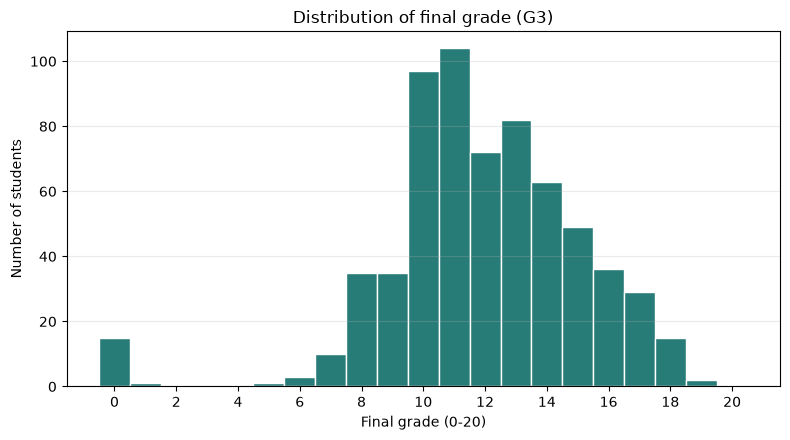

count    649.00
mean      11.91
std        3.23
min        0.00
25%       10.00
50%       12.00
75%       14.00
max       19.00
Name: G3, dtype: float64


In [42]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df['G3'], bins=np.arange(-0.5, 21.5, 1), color='#287C78', edgecolor='white')
ax.set(title='Distribution of final grade (G3)', xlabel='Final grade (0-20)', ylabel='Number of students')
ax.set_xticks(range(0, 21, 2))
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()
print(df['G3'].describe().round(2))

**Nhận xét:** `G3` tập trung chủ yếu trong khoảng 10-14 (Q1=10, median=12, Q3=14), trung bình 11.91. Phân phối có một số điểm 0 và hơi lệch về phía điểm cao; điểm 0 cần được hiểu theo quy tắc chấm của bộ dữ liệu, không mặc định là thiếu dữ liệu.

## 5. EDA — `absences` và outlier trực quan

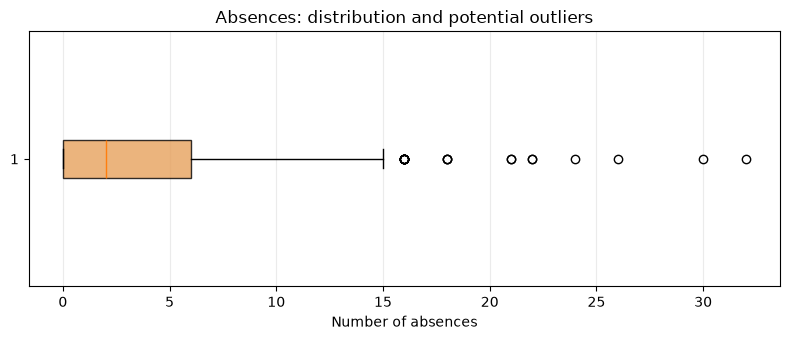

,count,mean,std,min,25%,50%,75%,max
absences,649.0,3.66,4.64,0.0,0.0,2.0,6.0,32.0


In [43]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot(df['absences'], orientation='horizontal', patch_artist=True,
           boxprops={'facecolor': '#E6A15C', 'alpha': 0.8})
ax.set(title='Absences: distribution and potential outliers', xlabel='Number of absences')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()
display(df['absences'].describe().to_frame().T.round(2))

**Trả lời:** Không nên tự động xóa mọi điểm bất thường. Giá trị cao có thể là lỗi nhập liệu, nhưng cũng có thể phản ánh số buổi nghỉ thực tế và chứa tín hiệu quan trọng. Cần xác minh theo nguồn/định nghĩa, xem ảnh hưởng tới phân tích và chỉ sửa hoặc loại khi có bằng chứng lỗi; nếu hợp lệ có thể giữ, dùng phương pháp robust hoặc phân tích độ nhạy.

## 6. So sánh các nhóm

G3 by internet:


,count,mean,median,std
internet,,,,
no,151,11.03,11.0,3.45
yes,498,12.17,12.0,3.12


G3 by higher:


,count,mean,median,std
higher,,,,
no,69,8.80,10.0,2.97
yes,580,12.28,12.0,3.06


G3 by studytime:


,count,mean,median,std
studytime,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04


G3 by failures:


,count,mean,median,std
failures,,,,
0,549,12.51,12.0,2.83
1,70,8.64,10.0,3.44
2,16,8.81,9.5,3.21
3,14,8.07,8.5,2.79


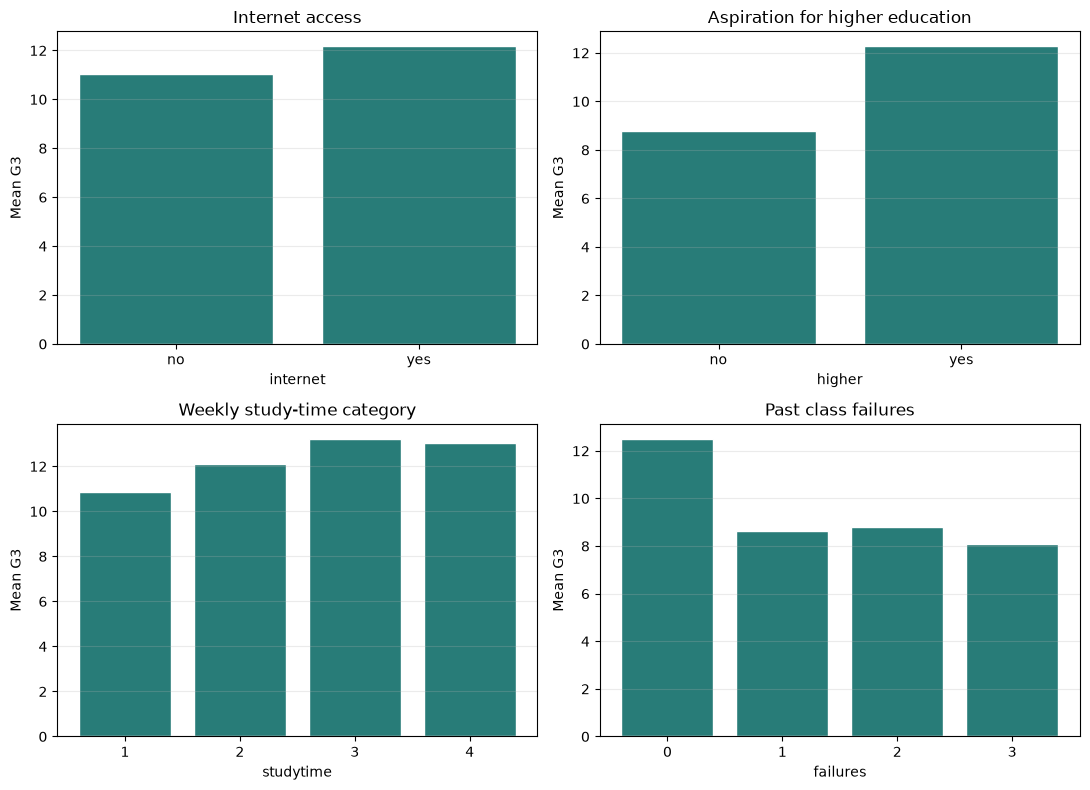

In [44]:
group_specs = [('internet', 'Internet access'), ('higher', 'Aspiration for higher education'),
               ('studytime', 'Weekly study-time category'), ('failures', 'Past class failures')]
group_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (column, title) in zip(axes.flat, group_specs):
    grouped = df.groupby(column, observed=True)['G3'].agg(['count', 'mean', 'median', 'std'])
    group_tables[column] = grouped
    print(f'G3 by {column}:')
    display(grouped.round(2))
    ax.bar(grouped.index.astype(str), grouped['mean'], color='#287C78', edgecolor='white')
    ax.set(title=title, xlabel=column, ylabel='Mean G3')
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

**Nhận xét và câu hỏi nhân quả:** Nhóm có Internet có `G3` trung bình 12.17 so với 11.03 ở nhóm không có; nhóm muốn học lên cao trung bình 12.28 so với 8.80. `G3` trung bình tăng từ 10.84 ở studytime mức 1 lên 13.23 ở mức 3, rồi gần như giữ ở mức 4 (13.06). Nhóm không có lần trượt nào trung bình 12.51, cao hơn nhóm có ít nhất một lần trượt (khoảng 8.07-8.81). Đây là khác biệt mô tả, không chứng minh nguyên nhân. Chênh lệch Internet có thể bị ảnh hưởng bởi kinh tế, nơi ở, hỗ trợ gia đình, điểm trước đó và cách chọn mẫu; cần thiết kế/nghiên cứu nhân quả phù hợp để kết luận Internet gây điểm cao hơn.

## 7. Correlation Analysis

Correlations with G3:


,correlation
G2,0.919
G1,0.826
studytime,0.250
Medu,0.240
Fedu,0.212
famrel,0.063
goout,-0.088
absences,-0.091
health,-0.099
age,-0.107


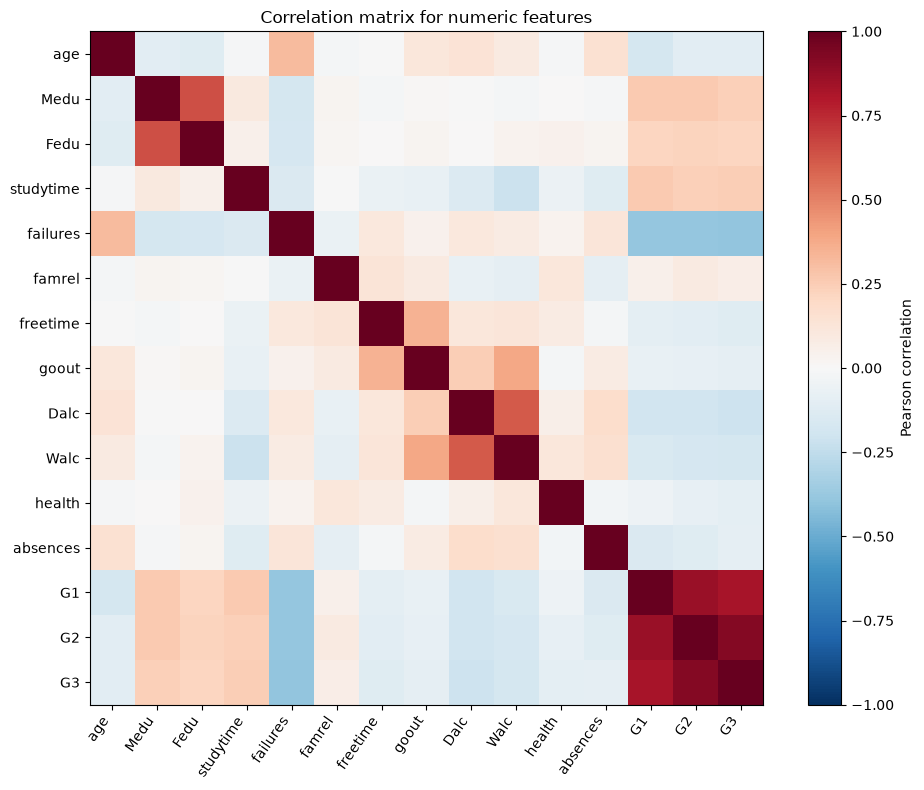

In [45]:
num_cols = [
    'age','Medu','Fedu','studytime','failures','famrel','freetime',
    'goout','Dalc','Walc','health','absences','G1','G2','G3'
]

corr_matrix = df[num_cols].corr()
corr_with_G3 = corr_matrix['G3'].drop('G3').sort_values(ascending=False)
print('Correlations with G3:')
display(corr_with_G3.to_frame('correlation').round(3))
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=55, ha='right')
ax.set_yticks(range(len(num_cols)), num_cols)
ax.set_title('Correlation matrix for numeric features')
fig.colorbar(image, ax=ax, label='Pearson correlation')
plt.tight_layout()
plt.show()

**Nhận xét về G1/G2 và nguy cơ leakage theo prediction time:** `G2` (r = **0.919**) và `G1` (r = **0.826**) có tương quan dương rất mạnh với `G3`, một phần hợp lý vì điểm các kỳ phản ánh năng lực học tập liên tiếp. Tuy nhiên, chỉ được dùng điểm nào đã có sẵn tại thời điểm dự đoán: cả hai không hợp lệ ở đầu năm; sau kỳ 1 có thể dùng `G1` nhưng chưa được dùng `G2`; sau kỳ 2 có thể dùng cả `G1` và `G2` để dự đoán `G3`. Đưa điểm tương lai vào feature sẽ gây target leakage và làm đánh giá quá lạc quan.

## 8. Tạo dirty dataset có kiểm soát
Chạy cell sau nguyên trạng để mọi nhóm có cùng lỗi dữ liệu.

In [46]:
dirty = df.copy()
rng = np.random.default_rng(42)

# Missing ở studytime
idx = rng.choice(dirty.index, size=20, replace=False)
dirty.loc[idx, 'studytime'] = np.nan

# Missing ở Mjob
idx = rng.choice(dirty.index, size=15, replace=False)
dirty.loc[idx, 'Mjob'] = np.nan

# Category không nhất quán
idx = rng.choice(dirty.index, size=8, replace=False)
dirty.loc[idx, 'school'] = 'gp'

# Duplicate 5 dòng đầu
dirty = pd.concat([dirty, dirty.iloc[:5]], ignore_index=True)

# Extreme value có chủ đích
dirty.loc[0, 'absences'] = 250

print('Dirty shape:', dirty.shape)


Dirty shape: (654, 33)


## 9. Data Cleaning

In [47]:
rows_before = len(dirty)
missing_before = dirty[['studytime', 'Mjob']].isna().sum().to_dict()

dirty['school'] = dirty['school'].str.strip().str.upper()
duplicates_before = int(dirty.duplicated().sum())
dirty = dirty.drop_duplicates().reset_index(drop=True)
rows_after = len(dirty)
studytime_median = dirty['studytime'].median()
mjob_mode = dirty['Mjob'].mode().iloc[0]
dirty['studytime'] = dirty['studytime'].fillna(studytime_median)
dirty['Mjob'] = dirty['Mjob'].fillna(mjob_mode)

cleaning_log = pd.DataFrame([
    ('school', 'uppercase/strip', 'gp normalized to GP'),
    ('duplicates', 'normalize categories, then drop exact duplicates', f'{duplicates_before} removed; {rows_before} -> {rows_after} rows'),
    ('studytime', f'fill missing with median={studytime_median}', f'{missing_before["studytime"]} values filled'),
    ('Mjob', f'fill missing with mode={mjob_mode}', f'{missing_before["Mjob"]} values filled')
], columns=['issue', 'action', 'result'])
display(cleaning_log)
print('Dirty-data verification: missing injected =', missing_before,
      '| duplicate rows after category normalization =', duplicates_before)
print('Rows before/after:', rows_before, rows_after)
audit_clean = pd.DataFrame({
    'dtype': dirty.dtypes.astype(str), 'missing': dirty.isna().sum(),
    'missing_pct': (dirty.isna().mean() * 100).round(2), 'unique': dirty.nunique(dropna=False)
})
display(audit_clean)
print('Duplicates after cleaning:', int(dirty.duplicated().sum()))

,issue,action,result
0,school,uppercase/strip,gp normalized to GP
1,duplicates,"normalize categories, then drop exact duplicates",4 removed; 654 -> 650 rows
2,studytime,fill missing with median=2.0,20 values filled
3,Mjob,fill missing with mode=other,15 values filled


Dirty-data verification: missing injected = {'studytime': 20, 'Mjob': 15} | duplicate rows after category normalization = 4
Rows before/after: 654 650


,dtype,missing,missing_pct,unique
school,str,0,0.0,2
sex,str,0,0.0,2
age,int64,0,0.0,8
address,str,0,0.0,2
famsize,str,0,0.0,2
Pstatus,str,0,0.0,2
Medu,int64,0,0.0,5
Fedu,int64,0,0.0,5
Mjob,str,0,0.0,5
Fjob,str,0,0.0,5


Duplicates after cleaning: 0


**Giải thích:** `fillna(df.mean())` không phù hợp cho toàn bộ bảng vì các cột phân loại không có trung bình có ý nghĩa; với biến thứ bậc như `studytime`, trung bình còn có thể tạo giá trị không hợp lệ ngoài các mức 1-4. Điền thiếu phải theo kiểu biến và quy trình huấn luyện: median/mode là lựa chọn đơn giản, nhưng trong mô hình cần ước lượng bộ điền thiếu chỉ trên tập train để tránh leakage.

## 10. Outlier Detection bằng IQR

In [48]:
q1 = dirty['absences'].quantile(0.25)
q3 = dirty['absences'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = (dirty['absences'] < lower) | (dirty['absences'] > upper)
outliers = dirty.loc[outlier_mask, ['absences', 'G3']].copy()
outliers.index.name = 'student_index'
print(f'Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, lower={lower:.2f}, upper={upper:.2f}')
print('IQR outlier count:', len(outliers))
display(outliers.sort_values('absences', ascending=False))

# The value 250 was deliberately injected in section 8; restore the known source value.
injected_error = dirty['absences'] >= 200
if injected_error.any():
    dirty.loc[injected_error, 'absences'] = df.loc[0, 'absences']
    print(f'Restored {int(injected_error.sum())} injected absences error(s) from the source row.')

Q1=0.00, Q3=6.00, IQR=6.00, lower=-9.00, upper=15.00
IQR outlier count: 22


,absences,G3
student_index,,
0,250,11
197,32,14
212,30,16
256,26,8
150,24,9
155,22,6
325,22,10
217,21,13
413,21,10


Restored 1 injected absences error(s) from the source row.


**Phân loại:** `absences=250` tại dòng 0 là **Data Error** đã được cài ở mục 8; giá trị nguồn là 4 nên đã khôi phục, không winsorize tùy tiện. Các giá trị từ 16 đến 32 là **Potential Real Extreme Value** hoặc **Need Domain Verification**: cần kiểm tra sổ điểm/định nghĩa kỳ học trước khi sửa hay loại. IQR chỉ gắn cờ quan sát xa phân bố, không chứng minh rằng quan sát sai.

## 11. One-hot Encoding

In [49]:
nominal_cols = ['school','sex','address','famsize','Pstatus','Mjob','Fjob','reason','guardian']

shape_before_encoding = dirty.shape
encoded_df = pd.get_dummies(dirty, columns=nominal_cols, dtype=int)
print('Shape before encoding:', shape_before_encoding)
print('Shape after encoding:', encoded_df.shape)
print('Encoded columns:', len(encoded_df.columns) - (len(dirty.columns) - len(nominal_cols)))
display(encoded_df.head())

Shape before encoding: (650, 33)
Shape after encoding: (650, 51)
Encoded columns: 27


,age,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,...,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other
0,18,4,4,2,2.0,0,yes,no,no,no,...,0,0,1,1,0,0,0,0,1,0
1,17,1,1,1,2.0,0,no,yes,no,no,...,1,0,0,1,0,0,0,1,0,0
2,15,1,1,1,2.0,0,yes,no,no,no,...,1,0,0,0,0,1,0,0,1,0
3,15,4,2,1,3.0,0,no,yes,no,yes,...,0,1,0,0,1,0,0,0,1,0
4,16,3,3,1,2.0,0,no,yes,no,no,...,1,0,0,0,1,0,0,1,0,0


## 12. Scaling

In [50]:
from sklearn.preprocessing import StandardScaler

features_scale = ['age','studytime','failures','absences']
scaler = StandardScaler()
scaled_df = pd.DataFrame(
    scaler.fit_transform(dirty[features_scale]),
    columns=features_scale,
    index=dirty.index
)
display(scaled_df.describe().round(3))
print('Scaled means:', scaled_df.mean().round(6).to_dict())
print('Scaled standard deviations:', scaled_df.std(ddof=0).round(6).to_dict())

,age,studytime,failures,absences
count,650.000,650.000,650.000,650.000
mean,0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001
min,-1.434,-1.140,-0.374,-0.790
25%,-0.613,-1.140,-0.374,-0.790
50%,0.209,0.079,-0.374,-0.358
75%,1.030,0.079,-0.374,0.505
max,4.316,2.517,4.690,6.116


Scaled means: {'age': 0.0, 'studytime': -0.0, 'failures': -0.0, 'absences': -0.0}
Scaled standard deviations: {'age': 1.0, 'studytime': 1.0, 'failures': 1.0, 'absences': 1.0}


**Câu hỏi:** `absences` có thể chi phối Euclidean distance vì là số đếm có biên độ lớn hơn tuổi, studytime và failures; giá trị lỗi 250 sẽ chi phối đặc biệt mạnh. Vì vậy đã nhận diện/khôi phục lỗi được cài trước khi scale, rồi chuẩn hóa các feature số được chọn.

## 13. Similarity / Distance

In [51]:
from scipy.spatial.distance import euclidean, cityblock, cosine

student_a = scaled_df.iloc[0].to_numpy()
student_b = scaled_df.iloc[1].to_numpy()
distance_results = {
    'Euclidean': euclidean(student_a, student_b),
    'Manhattan': cityblock(student_a, student_b),
    'Cosine': cosine(student_a, student_b)
}
print('Student indices compared:', scaled_df.index[0], 'and', scaled_df.index[1])
for metric, distance in distance_results.items():
    print(f'{metric} distance: {distance:.4f}')

Student indices compared: 0 and 1
Euclidean distance: 0.9280
Manhattan distance: 1.2531
Cosine distance: 0.4611


**Diễn giải:** Với bốn đặc trưng đã chuẩn hóa, hai học viên đầu có khoảng cách Euclidean **0.9280**, Manhattan **1.2531** và cosine **0.4611**. Ba thước đo lượng hóa khác nhau: Euclidean nhạy với sai khác bình phương, Manhattan cộng độ lệch tuyệt đối, còn cosine so hướng vector; khoảng cách nhỏ hơn thể hiện gần hơn theo metric tương ứng.

## 14. Tìm 5 học viên gần nhất

In [52]:
from sklearn.metrics import pairwise_distances

pairwise_euclidean = pairwise_distances(scaled_df, metric='euclidean')
query_id = 0
nearest_ids = np.argsort(pairwise_euclidean[query_id])
nearest_ids = nearest_ids[nearest_ids != query_id][:5]
neighbor_view = dirty.loc[nearest_ids, features_scale + ['G1', 'G2', 'G3']].copy()
neighbor_view.insert(0, 'student_index', nearest_ids)
neighbor_view.insert(1, 'distance', pairwise_euclidean[query_id, nearest_ids].round(4))
print(f'Five nearest students to query_id={query_id}:')
display(neighbor_view.reset_index(drop=True))

Five nearest students to query_id=0:


,student_index,distance,age,studytime,failures,absences,G1,G2,G3
0,649,0.0,18,2.0,0,4,0,11,11
1,601,0.0,18,2.0,0,4,8,8,10
2,422,0.0,18,2.0,0,4,10,13,13
3,309,0.0,18,2.0,0,4,10,12,14
4,239,0.0,18,2.0,0,4,8,8,8


**Kết luận ngắn:** Không. Năm láng giềng gần nhất ở đây giống nhau trên bốn đặc trưng được chọn nên khoảng cách bằng 0, nhưng `G3` của họ vẫn khác nhau (8-14). Độ gần chỉ mang nghĩa tương tự trên các feature/metric được dùng, không đảm bảo cùng điểm; cần đánh giá thêm feature, nhiễu và mức bất định.

## 15. Data Leakage theo Prediction Time
Điền bảng sau bằng Có/Không và giải thích.

| Scenario | Prediction time | Dùng G1? | Dùng G2? | Giải thích |
|---|---|---|---|---|
| A | Đầu năm | Không | Không | Cả hai điểm chưa được quan sát tại thời điểm dự đoán; dùng sẽ gây leakage. |
| B | Sau kỳ 1 | Có | Không | G1 đã có; G2 và G3 thuộc tương lai. |
| C | Sau kỳ 2 | Có | Có | G1, G2 đã có thể quan sát; G3 vẫn là target cần dự đoán. |

## 16. Tạo Mining-Ready Dataset cho early warning đầu học kỳ

In [53]:
target = (dirty['G3'] < 10).astype(int).rename('y')
X_raw = dirty.drop(columns=['G1', 'G2', 'G3'])
X_early = pd.get_dummies(X_raw, dtype=int)
mining_ready = pd.concat([X_early, target], axis=1)
output_path = Path('mining_ready_early_warning.csv')
mining_ready.to_csv(output_path, index=False)

assert not {'G1', 'G2', 'G3'}.intersection(X_early.columns)
assert mining_ready.isna().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in mining_ready.dtypes)
print('Saved:', output_path.resolve())
print('Dataset shape:', mining_ready.shape)
print('Target counts (0=pass, 1=G3<10):', target.value_counts().sort_index().to_dict())
print('Raw predictors before one-hot:', X_raw.shape[1], '| model-ready predictors:', X_early.shape[1])
display(mining_ready.head())

Saved: D:\learning\knowledge-discovery-and-data-mining\sources\mining_ready_early_warning.csv
Dataset shape: (650, 57)
Target counts (0=pass, 1=G3<10): {0: 550, 1: 100}
Raw predictors before one-hot: 30 | model-ready predictors: 56


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,y
0,18,4,4,2,2.0,0,4,3,4,1,...,0,0,1,0,1,1,0,1,0,0
1,17,1,1,1,2.0,0,5,3,3,1,...,0,1,0,0,1,0,1,1,0,0
2,15,1,1,1,2.0,0,4,3,2,2,...,0,0,1,0,1,0,1,1,0,0
3,15,4,2,1,3.0,0,3,2,2,1,...,1,0,1,0,1,0,1,0,1,0
4,16,3,3,1,2.0,0,4,3,2,1,...,0,0,1,0,1,1,0,1,0,0


## Kết luận
Điểm đáng chú ý nhất là `G3` tương quan mạnh với `G2` (r = 0.919) và `G1` (r = 0.826); nhóm chưa từng trượt có `G3` trung bình 12.51, cao hơn nhóm từng trượt (8.07-8.81). Đây là liên hệ mô tả, không chứng minh nhân quả. Dữ liệu gốc có 649 học viên, 33 biến, không missing và không duplicate. Bản dirty được cài 20 missing ở `studytime`, 15 ở `Mjob`, category `school` không nhất quán, bản sao và `absences=250`. Cleaning chuẩn hóa category, loại 4 duplicate chính xác, điền thiếu bằng median/mode và khôi phục giá trị absences lỗi từ nguồn. IQR cũng gắn cờ absences từ 16 đến 32; các giá trị này cần xác minh, không tự động loại. EDA bị giới hạn vì dữ liệu quan sát không kiểm soát yếu tố gây nhiễu và chưa chứng minh tính đại diện quần thể. Hai nguy cơ leakage là dùng `G1`/`G2` trước khi có điểm kỳ tương ứng, và fit imputer/encoder/scaler trên toàn bộ dữ liệu trước khi chia train/test. CSV early-warning có 650 dòng, 56 feature one-hot và nhãn `y=1` khi `G3<10`; `G1`, `G2`, `G3` không nằm trong feature. Dữ liệu đủ để bắt đầu Bài 5, nhưng cần chia train/test trước, fit preprocessing trên train, đánh giá phân lớp mất cân bằng và bảo đảm feature tồn tại đúng thời điểm dự đoán.

## 18. Checklist nộp bài
- [x] Notebook chạy từ đầu đến cuối
- [x] Có Data Quality Audit
- [x] Có ít nhất 4 biểu đồ EDA và diễn giải
- [x] Có cleaning log
- [x] Có distance comparison
- [x] Có leakage analysis
- [x] Có `mining_ready_early_warning.csv`
- [x] Có kết luận 150-250 từ